In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from gudhi import AlphaComplex, SimplexTree
from gudhi.representations import BettiCurve
from utils import *

# Dataset and L-fuzzy values

In [2]:
data = np.array([
    [ 0,  0],
    [ 0, -2],
    [ 2,  0],
    [ 2, -2],
    [ 3,  0],
    [ 3, -2],
    [ 4, -1]
])
fuzzy_values_01 = [1.,1.,0.8,0.8,0.5,0.5,0.6]
fuzzy_values_xy = ['x','x','x','x','y','y','y']

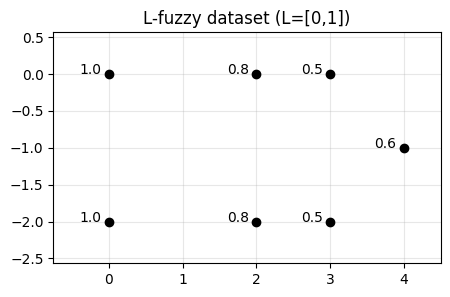

In [3]:
plt.figure(figsize=(5, 3))
plt.scatter(data[:, 0], data[:, 1],color='k',zorder=3)
for i in range(len(data)):
    plt.text(data[i, 0]-0.1, data[i, 1], str(fuzzy_values_01[i]), fontsize=10, ha='right',zorder=4)
plt.xlabel('')
plt.title('L-fuzzy dataset (L=[0,1])')
plt.axis('equal')
plt.grid(True,alpha=0.3,zorder=0)
plt.xlim(-0.75,4.5)
plt.savefig('plots/01_dataset.pdf')
plt.show()

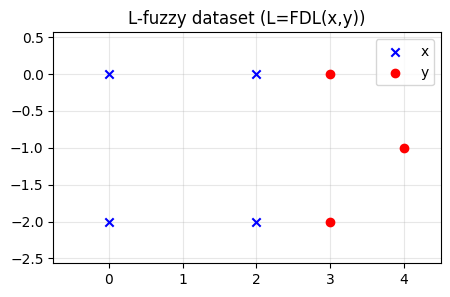

In [4]:
plt.figure(figsize=(5, 3))
mask_x = np.array([f == 'x' for f in fuzzy_values_xy])
mask_y = ~mask_x
plt.scatter(data[mask_x, 0], data[mask_x, 1], c='b', marker='x', label='x', zorder=3)
plt.scatter(data[mask_y, 0], data[mask_y, 1], c='r', marker='o', label='y', zorder=3)
plt.title('L-fuzzy dataset (L=FDL(x,y))')
plt.axis('equal')
plt.grid(True, alpha=0.3, zorder=0)
plt.legend()
plt.xlim(-0.75, 4.5)
plt.savefig('plots/xy_dataset.pdf')
plt.show()

# Crisp curves

In [5]:
homology_coeff_field = 2
predefined_grid = np.arange(0,2.5,0.1)

In [6]:
alpha = AlphaComplex(points=data)
simplex_tree = alpha.create_simplex_tree(output_squared_values=False)
simplex_tree.compute_persistence(homology_coeff_field=homology_coeff_field, persistence_dim_max=True)

### Curve for d=0

In [7]:
H0 = simplex_tree.persistence_intervals_in_dimension(0)
H0

array([[0.        , 0.5       ],
       [0.        , 0.5       ],
       [0.        , 0.70710678],
       [0.        , 0.70710678],
       [0.        , 1.        ],
       [0.        , 1.        ],
       [0.        ,        inf]])

In [8]:
bc0 = BettiCurve(predefined_grid=predefined_grid)
curve0 = bc0.fit_transform([H0])
curve0

array([[7, 7, 7, 7, 7, 5, 5, 5, 3, 3, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 1, 1]])

### Curve for d=1

In [9]:
H1 = simplex_tree.persistence_intervals_in_dimension(1)
H1

array([[1.        , 1.11803399],
       [1.        , 1.41421356]])

In [10]:
bc1 = BettiCurve(predefined_grid=predefined_grid)
curve1 = bc1.fit_transform([H1])
curve1

array([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 2, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0]])

### Euler characteristic

In [11]:
euler = curve0-curve1

# L-fuzzy Betti curves for values in [0,1]

In [12]:
nbins = 10
labels = [f'From {i/nbins} to {(i+1)/nbins}' for i in range(nbins)]
fbcurves_01 = FuzzyBettiCurve(simplex_tree=simplex_tree, fuzzy_values=fuzzy_values_01, predefined_grid=predefined_grid, bins=nbins)

We check whether the sum of all L-fuzzy Betti curves recovers the original crisp Betti curve

In [13]:
np.allclose(curve0, fbcurves_01[0].sum(axis=0)) and np.allclose(curve1, fbcurves_01[1].sum(axis=0))

True

### Curves for d=0

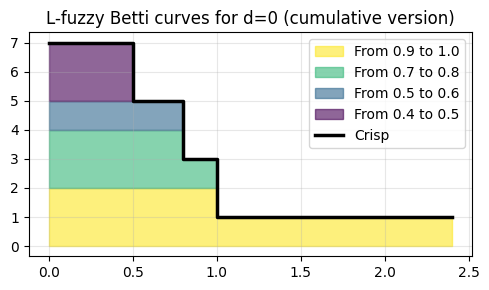

In [14]:
x = predefined_grid
plt.figure(figsize=(5, 3))
non_null_indices = [(i, row) for i, row in enumerate(fbcurves_01[0]) if np.any(row)][::-1]
colors = plt.cm.viridis(np.linspace(0, 1, len(non_null_indices)))[::-1]
cumulative = np.zeros_like(x)
for color, (i, row) in zip(colors, non_null_indices):
    new_cumulative = cumulative + row
    plt.fill_between(x, cumulative, new_cumulative, color=color, alpha=0.6,
                     label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, curve0[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Betti curves for d=0 (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('plots/01_betti0.pdf')
plt.show()

### Curves for d=1

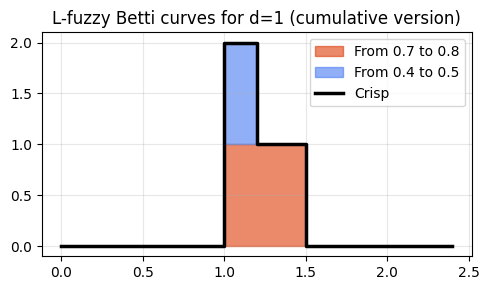

In [15]:
x = predefined_grid
plt.figure(figsize=(5, 3))
non_null_indices = [(i, row) for i, row in enumerate(fbcurves_01[1]) if np.any(row)][::-1]
colors = plt.cm.turbo(np.linspace(0.15, 0.85, len(non_null_indices)))[::-1]
cumulative = np.zeros_like(x)
for color, (i, row) in zip(colors, non_null_indices):
    new_cumulative = cumulative + row
    plt.fill_between(x, cumulative, new_cumulative, color=color, alpha=0.6,
                     label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, curve1[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Betti curves for d=1 (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig('plots/01_betti1.pdf')
plt.show()

### Euler characteristic curve

In [16]:
feuler_01 = FuzzyEulerCharacteristic(fbcurves_01)

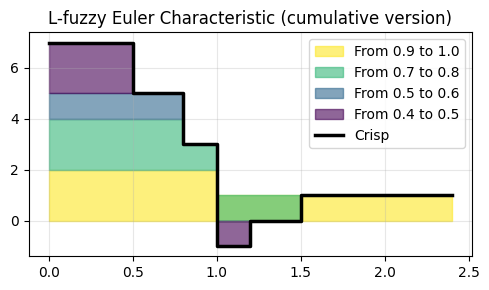

In [17]:
x = predefined_grid
plt.figure(figsize=(5, 3))
non_null_indices = [(i, row) for i, row in enumerate(feuler_01) if np.any(row)][::-1]
colors = plt.cm.viridis(np.linspace(0, 1, len(non_null_indices)))[::-1]
cumulative = np.zeros_like(x)
for color, (i, row) in zip(colors, non_null_indices):
    new_cumulative = cumulative + row
    plt.fill_between(x, cumulative, new_cumulative, color=color, alpha=0.6,
                     label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, euler[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Euler Characteristic (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig('plots/01_euler.pdf')
plt.show()

# L-fuzzy Betti curves for values in FDL(x,y)

In [18]:
fbcurves_xy = FuzzyBettiCurve(simplex_tree=simplex_tree, fuzzy_values=fuzzy_values_xy, predefined_grid=predefined_grid)

We check again whether the sum of all L-fuzzy Betti curves recovers the original crisp Betti curve

In [19]:
np.allclose(curve0, fbcurves_xy[0].sum(axis=0)) and np.allclose(curve1, fbcurves_xy[1].sum(axis=0))

True

### Curves for d=0

In [20]:
x = predefined_grid
labels = ['x and y', 'x', 'y', 'x or y']
colors = ['purple', 'blue', 'red', 'green']

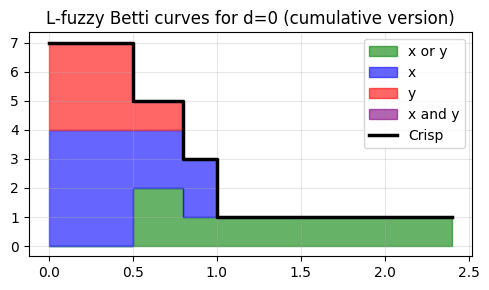

In [21]:
plt.figure(figsize=(5, 3))
cumulative = np.zeros_like(x)
for i in [3,1,2,0]:
    new_cumulative = cumulative + fbcurves_xy[0][i]
    plt.fill_between(x, cumulative, new_cumulative, color=colors[i], alpha=0.6, label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, curve0[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Betti curves for d=0 (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('plots/xy_betti0.pdf')
plt.show()

### Curves for d=1

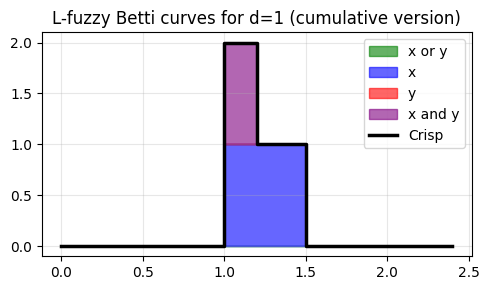

In [22]:
plt.figure(figsize=(5, 3))
cumulative = np.zeros_like(x)
for i in [3,1,2,0]:
    new_cumulative = cumulative + fbcurves_xy[1][i]
    plt.fill_between(x, cumulative, new_cumulative, color=colors[i], alpha=0.6, label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, curve1[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Betti curves for d=1 (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('plots/xy_betti1.pdf')
plt.show()

### Euler characteristic curve

In [23]:
feuler_xy = FuzzyEulerCharacteristic(fbcurves_xy)

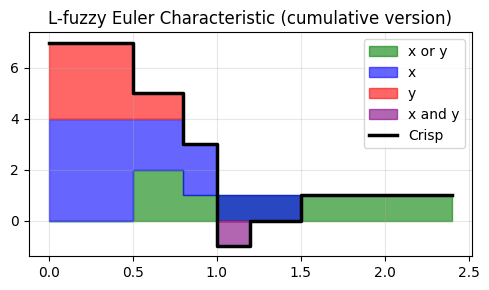

In [24]:
plt.figure(figsize=(5, 3))
cumulative = np.zeros_like(x)
for i in [3,1,2,0]:
    new_cumulative = cumulative + feuler_xy[i]
    plt.fill_between(x, cumulative, new_cumulative, color=colors[i], alpha=0.6, label=labels[i],step='post')
    cumulative = new_cumulative
plt.step(x, euler[0], where="post", color="black", linewidth=2.5, label="Crisp")
plt.title('L-fuzzy Euler Characteristic (cumulative version)')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig('plots/xy_euler.pdf')
plt.show()